In [31]:
pip install numpy pandas seaborn matplotlib plotly wordcloud


   ---------------------------------------- 0.0/301.2 kB ? eta -:--:--
   ---------------------------------------- 0.0/301.2 kB ? eta -:--:--
   - -------------------------------------- 10.2/301.2 kB ? eta -:--:--
   -- ------------------------------------ 20.5/301.2 kB 165.2 kB/s eta 0:00:02
   ----- --------------------------------- 41.0/301.2 kB 245.8 kB/s eta 0:00:02
   ----------- --------------------------- 92.2/301.2 kB 476.3 kB/s eta 0:00:01
   ----------------------------- -------- 235.5/301.2 kB 962.7 kB/s eta 0:00:01
   ---------------------------------------- 301.2/301.2 kB 1.0 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [147]:
df = pd.read_csv('../DATA/AvitoData.csv')


In [149]:
data.shape


(47080, 12)

In [151]:
data.duplicated().sum()

2148

In [153]:
df = data.drop_duplicates(keep='first').reset_index(drop=True)
df.shape

(44932, 12)

In [155]:
df.isna().sum()

url                   0
year               1311
type_boit          1453
type_carburant     1292
kilometrage        1323
marke              1327
model              1327
puissance          1433
premiere_main      7725
Nombre_doors       6720
city                  2
price             11718
dtype: int64

In [157]:
df.head()

,url,year,type_boit,type_carburant,kilometrage,marke,model,puissance,premiere_main,Nombre_doors,city,price
0,https://www.avito.ma/fr/ain_sebaa/voitures_d'o...,2021,Automatique,Essence,60 000 - 64 999,Fiat,500,7 CV,Oui,5.0,"Ain Sebaa, Casablanca",159 000 DH
1,https://www.avito.ma/fr/maarif/voitures_d'occa...,2025,Automatique,Diesel,0 - 4 999,BMW,Série 4,8 CV,Oui,3.0,"Maarif, Casablanca",NaN
2,https://www.avito.ma/fr/2_mars/voitures_de_loc...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"2 Mars, Casablanca",200 DH
3,https://www.avito.ma/fr/oulfa/voitures_d'occas...,2022,Automatique,Diesel,40 000 - 44 999,Volkswagen,Touareg,12 CV,Oui,5.0,"Oulfa, Casablanca",NaN
4,https://www.avito.ma/fr/maarif/voitures_d'occa...,2025,Automatique,Diesel,0 - 4 999,Audi,Q8,12 CV,NaN,5.0,"Maarif, Casablanca",NaN


<Axes: >

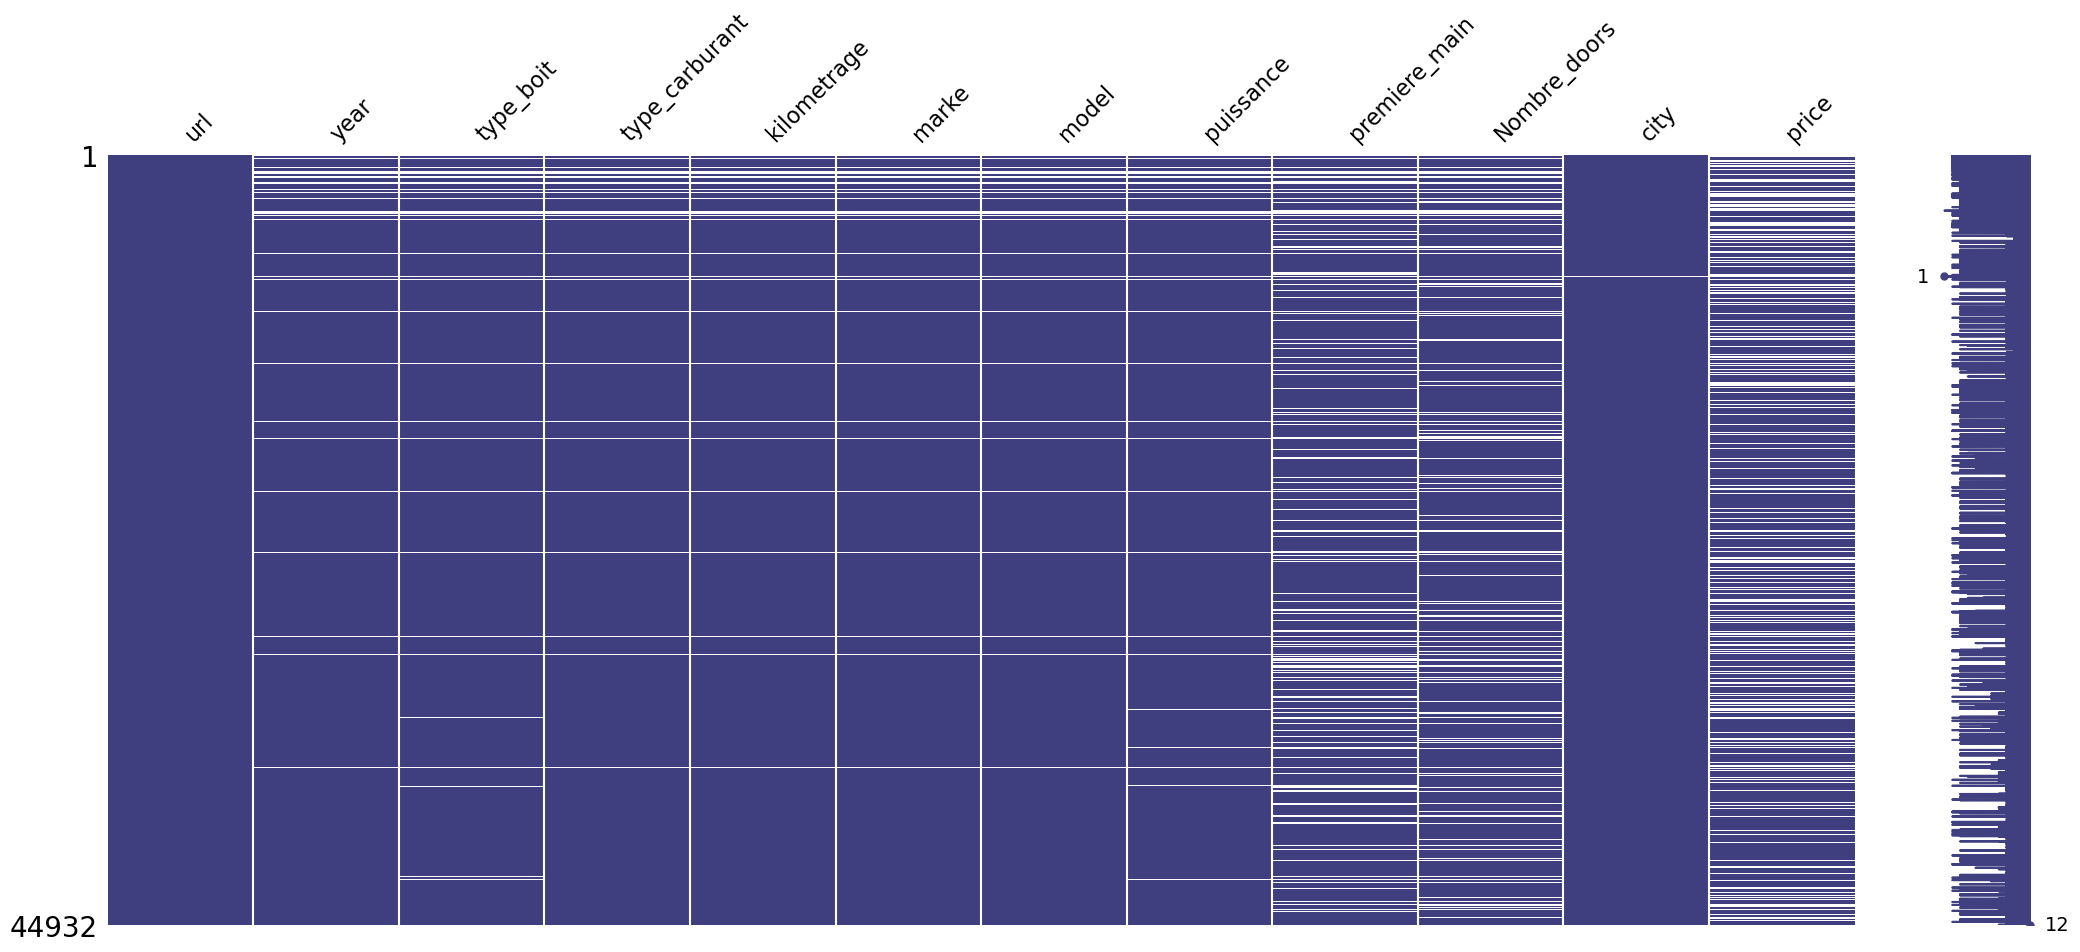

In [159]:
import missingno as msno
msno.matrix(df, color = (0.25, 0.25, 0.5))

In [161]:
seuil = len(df) * 0.5
to_drop = df.columns[df.isna().sum() > seuil]
df.drop(columns=to_drop, inplace=True)
df.shape

(44932, 12)

In [163]:
df =df.dropna(subset=['price'])
df = df.dropna(subset=['type_boit'])
df = df.dropna(subset=['type_carburant'])
df = df.dropna(subset=['kilometrage'])
df = df.dropna(subset=['marke'])
df= df.dropna(subset=['model'])
df= df.dropna(subset=['puissance'])
df = df.dropna(subset=['price'])

In [165]:
df.shape

(31969, 12)

In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31969 entries, 0 to 44931
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   url             31969 non-null  object 
 1   year            31969 non-null  object 
 2   type_boit       31969 non-null  object 
 3   type_carburant  31969 non-null  object 
 4   kilometrage     31969 non-null  object 
 5   marke           31969 non-null  object 
 6   model           31969 non-null  object 
 7   puissance       31969 non-null  object 
 8   premiere_main   27860 non-null  object 
 9   Nombre_doors    28580 non-null  float64
 10  city            31969 non-null  object 
 11  price           31969 non-null  object 
dtypes: float64(1), object(11)
memory usage: 3.2+ MB


In [169]:
df['price'] = df['price'].str.replace('DH', '', regex=False).str.replace('\u202f' , '').str.replace(' ' , '').astype(int)


In [171]:
def clean_kilometrage_column(row):
        parts = row.split('-')
        kilometrage = []
        for k in parts:
            if 'Plus de' in k:
                  k = k.replace('Plus de', '')  
            ki = k.replace(' ', '')
            ki = int(ki)
            kilometrage.append(ki)
        if(len(kilometrage)== 1) : 
              kilometrage = kilometrage[0]
              return kilometrage

        if(len(kilometrage)==2) : 
            kilometrage = (kilometrage[0]+kilometrage[1])//2
            return kilometrage

        
df['kilometrage'] = df['kilometrage'].apply(clean_kilometrage_column)

In [173]:
print(df['kilometrage'].unique())

[ 62499 154999  97499  22499  72499 164999  92499 114999  42499 274999
  47499  12499  67499  27499 174999  57499 134999 194999 144999  82499
  77499  32499 104999 184999 124999 224999 324999   2499  17499  37499
  52499  87499   7499 374999 474999 424999 500000]


In [175]:
def clean_puissance_column(row):
    if 'Plus de' in row:
            row = row.replace('Plus de', '')  
    row = row.replace('CV', '')
    row = row.replace(' ', '')
    row = int(row)
    return row
df['puissance'] = df['puissance'].apply(clean_puissance_column)

In [177]:
df['type_carburant'] = df['type_carburant'].str.lower()
df['type_boit'] = df['type_boit'].str.lower()
df['marke'] = df['marke'].str.lower()
df['model'] = df['model'].str.lower()


In [179]:
df.head()

,url,year,type_boit,type_carburant,kilometrage,marke,model,puissance,premiere_main,Nombre_doors,city,price
0,https://www.avito.ma/fr/ain_sebaa/voitures_d'o...,2021,automatique,essence,62499,fiat,500,7,Oui,5.0,"Ain Sebaa, Casablanca",159000
5,https://www.avito.ma/fr/al_maghrib_al_arabi/vo...,2018,manuelle,diesel,154999,hyundai,creta,6,Oui,5.0,"Al Maghrib Al Arabi, Kénitra",175000
6,https://www.avito.ma/fr/ain_sebaa/voitures_d'o...,2021,automatique,diesel,97499,dacia,duster,6,Oui,5.0,"Ain Sebaa, Casablanca",187000
7,https://www.avito.ma/fr/anfa/voitures_d'occasi...,2018,automatique,diesel,22499,mercedes-benz,classe v,9,Oui,5.0,"Anfa, Casablanca",845000
8,https://www.avito.ma/fr/ain_sebaa/voitures_d'o...,2022,manuelle,diesel,62499,peugeot,208,6,Oui,5.0,"Ain Sebaa, Casablanca",168000


In [181]:
print(df['year'].unique())

['2021' '2018' '2022' '2019' '2013' '2023' '2003' '2016' '2005' '2015'
 '2011' '2020' '2014' '2024' '2017' '2008' '2009' '2004' '2010' '2025'
 '2006' '2012' '1980 ou plus ancien' '1988' '2002' '1996' '2000' '1987'
 '1999' '1990' '1992' '1998' '1994' '1985' '1991' '2007' '1993' '2001'
 '1989' '1986' '1984' '1995' '1997' '1983' '1981' '1982']


In [183]:
df['year'] = df['year'].str.replace(' ou plus ancien' , '').astype(int)
print(df['year'].unique())

[2021 2018 2022 2019 2013 2023 2003 2016 2005 2015 2011 2020 2014 2024
 2017 2008 2009 2004 2010 2025 2006 2012 1980 1988 2002 1996 2000 1987
 1999 1990 1992 1998 1994 1985 1991 2007 1993 2001 1989 1986 1984 1995
 1997 1983 1981 1982]


In [185]:
def clean_city_column(row):
        parts = row.split(',')
        if(len(parts) == 1) : 
            return parts[0].replace(' ', '').lower()
        else : 
              return parts[1].replace(' ', '').lower()
df['city'] = df['city'].apply(clean_city_column)

In [187]:
df['city'] = df['city'].str.replace('الدارالبيضاء' , 'casablanca')
df['city'] = df['city'].str.replace('سلا' , 'sala')
df['city'] = df['city'].str.replace('فاس' , 'fès')
df['city'] = df['city'].str.replace('مراكش' , 'marrakech')
df['city'] = df['city'].str.replace('الرباط' , 'rabat')
df['city'] = df['city'].str.replace('تطوان' , 'tétouan')
df['city'] = df['city'].str.replace('تمارة' , 'temara')
df['city'] = df['city'].str.replace('طنجة' , 'tanger')
df['city'] = df['city'].str.replace('أكادير' , 'agadir')


In [189]:
mode_doors = df['Nombre_doors'].mode()[0]
df['Nombre_doors'] = df['Nombre_doors'].fillna(mode_doors)


In [191]:
df.isna().sum()

url                  0
year                 0
type_boit            0
type_carburant       0
kilometrage          0
marke                0
model                0
puissance            0
premiere_main     4109
Nombre_doors         0
city                 0
price                0
dtype: int64

In [193]:
 def encode_premiere_main(val):
    if val == 'Non':
        return 0
    elif val == 'Oui':
        return 2
    else:  
        return 1

df['premiere_main'] = df['premiere_main'].apply(encode_premiere_main)

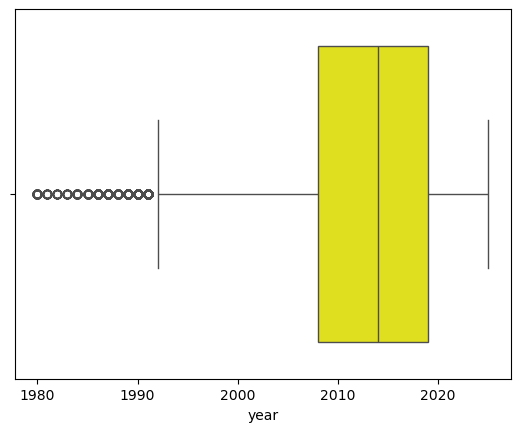

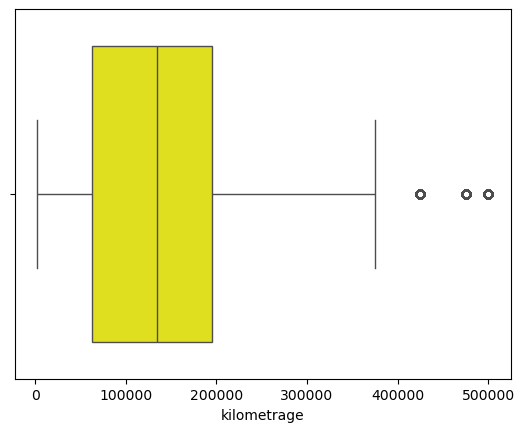

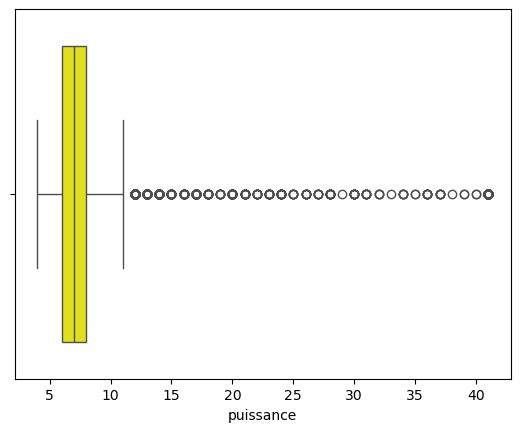

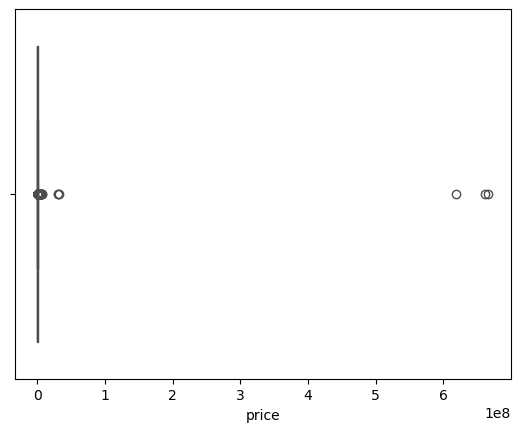

In [195]:
col = df.select_dtypes(exclude=['object']).drop(columns=['premiere_main' , 'Nombre_doors']).columns
for i in col:
    sns.boxplot(df[i], orient='h', color='yellow')
    plt.show()

In [196]:
from scipy import stats
def detect_outliers(df, column):

    z_scores = stats.zscore(df[column])
    threshold = 3
    outliers = df[np.abs(z_scores) > threshold][column]
    return outliers

def remove_outliers(df, column):
    z_scores = stats.zscore(df[column])
    threshold = 3
    new_df = df[np.abs(z_scores) < threshold]
    return new_df
col = df.select_dtypes(exclude=['object']).drop(columns=['premiere_main' , 'Nombre_doors']).columns
for i in col:
    out = detect_outliers(df, i)
    print(out)

256      1980
1635     1985
2443     1986
3155     1986
3329     1984
         ... 
44643    1985
44667    1985
44701    1986
44804    1981
44824    1984
Name: year, Length: 388, dtype: int32
889      474999
1965     500000
3586     500000
3590     474999
4549     474999
          ...  
44527    500000
44619    474999
44630    474999
44644    500000
44875    474999
Name: kilometrage, Length: 448, dtype: int64
94       17
136      17
212      17
233      17
935      41
         ..
43281    28
43408    20
43442    27
43983    17
44122    18
Name: puissance, Length: 375, dtype: int64
33394     31000000
36157    661280292
36238     32000000
38847    618818655
39950     30000000
40438    666339880
Name: price, dtype: int32


In [199]:
df = df[df['price'] >= 25000]
df = df[df['price'] <= 1000000]

col = df.select_dtypes(exclude=['object']).drop(columns=['premiere_main' , 'Nombre_doors']).columns
for i in col:
    df = remove_outliers(df, i)


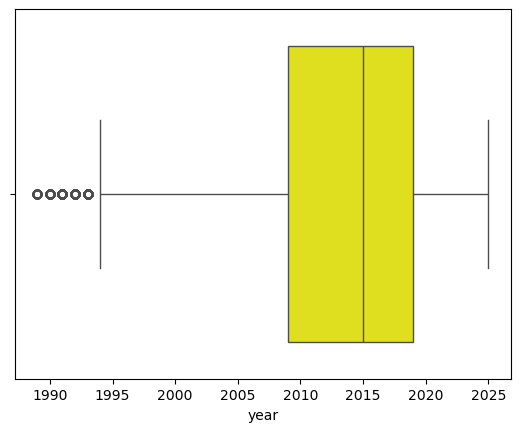

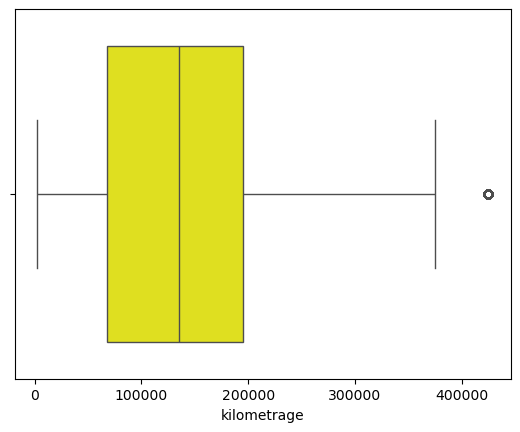

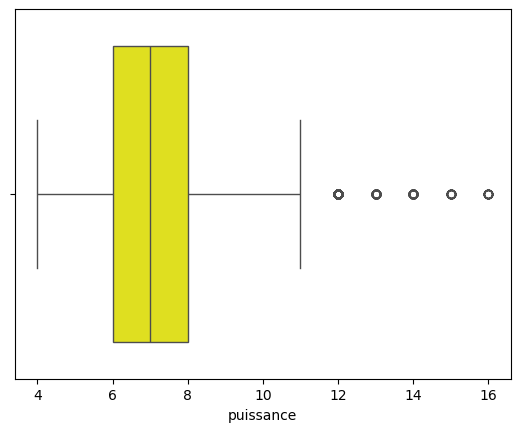

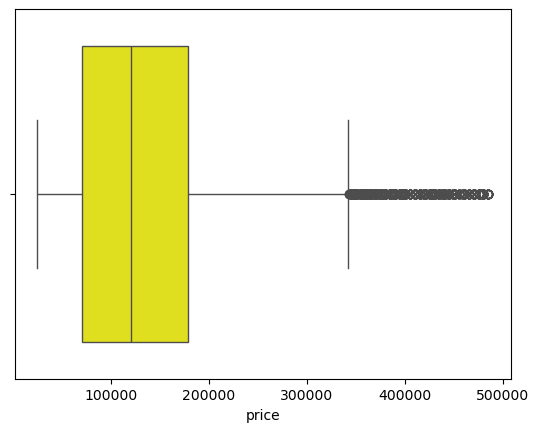

In [209]:
col = df.select_dtypes(exclude=['object']).drop(columns=['premiere_main' , 'Nombre_doors']).columns
for i in col:
    sns.boxplot(df[i], orient='h', color='yellow')
    plt.show()

In [211]:
df.shape

(29342, 12)

In [215]:
df.to_csv('../DATA/clean_data.csv', index=False)